In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

# Load the specified dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [2]:
# Clean column names
df.columns = df.columns.str.strip()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Encode target variable
df["Churn"] = (
    df["Churn"].astype(str).str.strip().map({"Yes": 1, "No": 0})
)

# Remove rows with missing target values
df = df.dropna(subset=["Churn"])
df["Churn"] = df["Churn"].astype(int)

# Remove customer identifier
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"]

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Split before preprocessing to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Calculate class imbalance from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

print("Preprocessing completed!")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTarget distribution:")
print(y.value_counts())

Preprocessing completed!
Numeric features: 4
Categorical features: 15
Training rows: 5634
Testing rows: 1409

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
predictions = {}
probabilities = {}
results = []

for name, model in models.items():
    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.to_csv("outputs/model_comparison.csv")

print("\nTraining completed!")
display(results_df.round(4))

Training Random Forest...
Training XGBoost...

Training completed!


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Random Forest,0.7637,0.5485,0.6203,0.5822,0.8225
XGBoost,0.7530,0.5231,0.7861,0.6282,0.8450


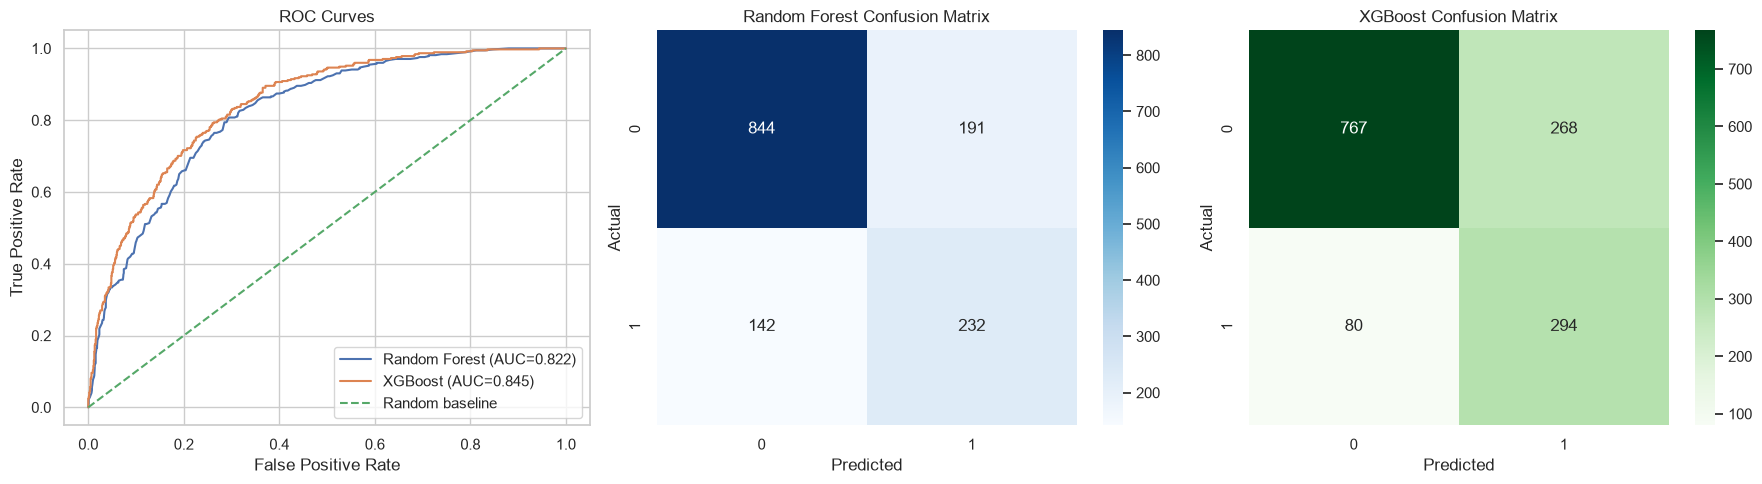


Classification Report: Random Forest
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409


Classification Report: XGBoost
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.82      1035
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409


ROC-AUC scores:
Model
Random Forest    0.8225
XGBoost          0.8450
Name: ROC-AUC, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC curves
for name in trained_models:
    fpr, tpr, _ = roc_curve(
        y_test, probabilities[name]
    )
    auc_score = roc_auc_score(
        y_test, probabilities[name]
    )

    axes[0].plot(
        fpr, tpr,
        label=f"{name} (AUC={auc_score:.3f})"
    )

axes[0].plot([0, 1], [0, 1], "--", label="Random baseline")
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# Random Forest confusion matrix
sns.heatmap(
    confusion_matrix(y_test, predictions["Random Forest"]),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# XGBoost confusion matrix
sns.heatmap(
    confusion_matrix(y_test, predictions["XGBoost"]),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[2]
)
axes[2].set_title("XGBoost Confusion Matrix")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("outputs/evaluation_results.png", dpi=300)
plt.show()

for name in trained_models:
    print(f"\nClassification Report: {name}")
    print(classification_report(
        y_test,
        predictions[name],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

print("\nROC-AUC scores:")
print(results_df["ROC-AUC"].round(4))

Best model: XGBoost
ROC-AUC: 0.845

Top 10 important features:


,Feature,Importance
36,categorical__Contract_Month-to-month,0.373532
16,categorical__InternetService_Fiber optic,0.070998
18,categorical__OnlineSecurity_No,0.059771
27,categorical__TechSupport_No,0.045546
19,categorical__OnlineSecurity_No internet service,0.041831
17,categorical__InternetService_No,0.036535
38,categorical__Contract_Two year,0.034919
15,categorical__InternetService_DSL,0.030322
35,categorical__StreamingMovies_Yes,0.021700
43,categorical__PaymentMethod_Electronic check,0.020289


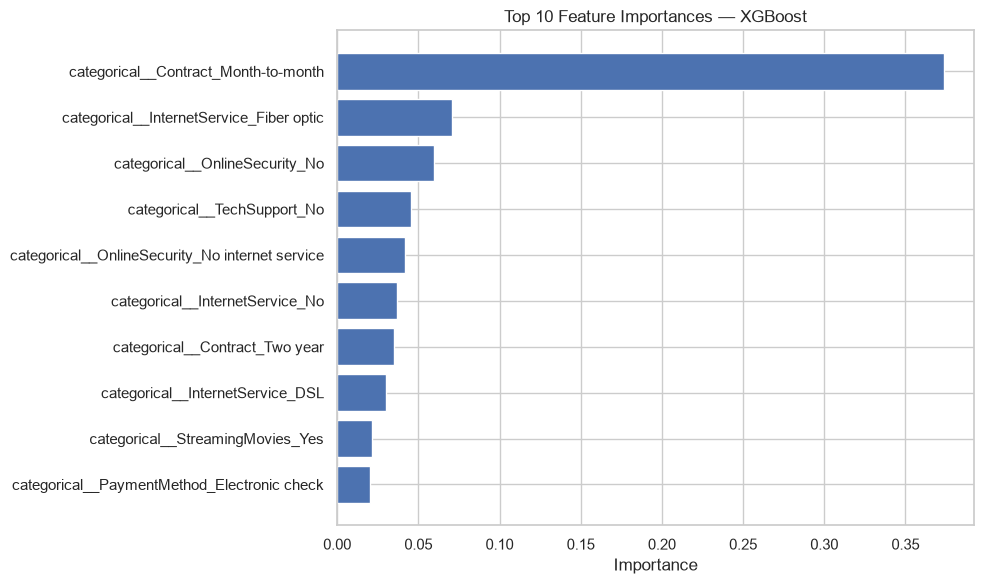

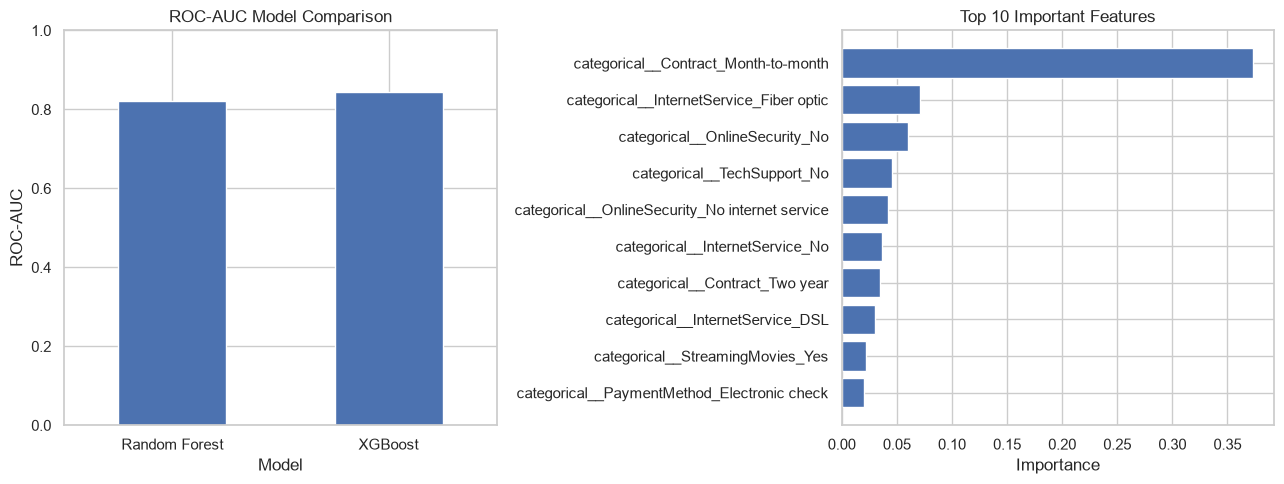


DATHEON TASK 3 COMPLETED
Best model: XGBoost
Best ROC-AUC: 0.845
Final visualization: output.png
Saved model: outputs/best_churn_model.pkl

Output files:
- best_churn_model.pkl
- churn_predictions.csv
- evaluation_results.png
- feature_importance.csv
- feature_importance.png
- model_comparison.csv


In [5]:
# Select the model with the highest ROC-AUC
best_model_name = results_df["ROC-AUC"].idxmax()
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("ROC-AUC:", round(
    results_df.loc[best_model_name, "ROC-AUC"], 4
))

# Extract feature importance
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
importance_values = fitted_estimator.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

print("\nTop 10 important features:")
display(importance_df.head(10))

importance_df.to_csv(
    "outputs/feature_importance.csv", index=False
)

# Plot top 10 features
top10 = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.title(f"Top 10 Feature Importances — {best_model_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=300)
plt.show()

# Save predictions
prediction_df = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy(),
    "Predicted_Churn": predictions[best_model_name],
    "Churn_Probability": probabilities[best_model_name]
})

prediction_df.to_csv(
    "outputs/churn_predictions.csv", index=False
)

# Save trained model
joblib.dump(best_model, "outputs/best_churn_model.pkl")

# Final output image
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

results_df["ROC-AUC"].plot(
    kind="bar", ax=axes[0], ylim=(0, 1),
    title="ROC-AUC Model Comparison"
)
axes[0].set_ylabel("ROC-AUC")
axes[0].tick_params(axis="x", rotation=0)

axes[1].barh(top10["Feature"], top10["Importance"])
axes[1].set_title("Top 10 Important Features")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.savefig("output.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n" + "=" * 45)
print("DATHEON TASK 3 COMPLETED")
print("=" * 45)
print("Best model:", best_model_name)
print("Best ROC-AUC:", round(
    results_df.loc[best_model_name, "ROC-AUC"], 4
))
print("Final visualization: output.png")
print("Saved model: outputs/best_churn_model.pkl")

print("\nOutput files:")
for filename in sorted(os.listdir("outputs")):
    print("-", filename)